In [33]:
import torch
from torch import nn


In [34]:
# set the device the agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [35]:
from requests.api import request
import requests
import zipfile
from pathlib import Path


# set the data path and image path
data_path = Path("data")
image_path = data_path / "pizza_steak_sushi"
zip_file_name = "pizza_steak_sushi.zip"
# check if the image_path directory exists
if image_path.is_dir():
  print(f"{image_path} directory exists.")
else:
  print(f"Did not find {image_path} directory, creating one...")
  # Create the image_path directory first
  image_path.mkdir(parents=True, exist_ok=True)

  # Define the full path for the zip file within the created directory
  zip_file_path = image_path / zip_file_name

  # Download the zip file
  print(f"Downloading {zip_file_name} data to {zip_file_path}...")
  # Correct the typo: requsts.get -> requests.get
  response = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")

  with open(zip_file_path, "wb") as f:
    f.write(response.content)

  # Unzip the file
  with zipfile.ZipFile(zip_file_path, "r") as zip_ref:
    print(f"Unzipping {zip_file_name} data into {image_path}...")
    zip_ref.extractall(image_path)


data\pizza_steak_sushi directory exists.


In [36]:
import os
# create function to walk through our datasets
def walk_through_dir(dir_path):
  for dirpath,dirnames,filenames in os.walk(dir_path):
    print(f" there are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}' ")

In [37]:
walk_through_dir(image_path)

 there are 2 directories and 1 images in 'data\pizza_steak_sushi' 
 there are 3 directories and 0 images in 'data\pizza_steak_sushi\test' 
 there are 0 directories and 25 images in 'data\pizza_steak_sushi\test\pizza' 
 there are 0 directories and 19 images in 'data\pizza_steak_sushi\test\steak' 
 there are 0 directories and 31 images in 'data\pizza_steak_sushi\test\sushi' 
 there are 3 directories and 0 images in 'data\pizza_steak_sushi\train' 
 there are 0 directories and 78 images in 'data\pizza_steak_sushi\train\pizza' 
 there are 0 directories and 75 images in 'data\pizza_steak_sushi\train\steak' 
 there are 0 directories and 72 images in 'data\pizza_steak_sushi\train\sushi' 


In [38]:
# create train and test path
train_dir= image_path / "train"
test_dir= image_path / "test"
train_dir, test_dir

(WindowsPath('data/pizza_steak_sushi/train'),
 WindowsPath('data/pizza_steak_sushi/test'))

Random image path: data\pizza_steak_sushi\test\sushi\2521706.jpg
Image class: sushi
Image height: 512
Image width: 384


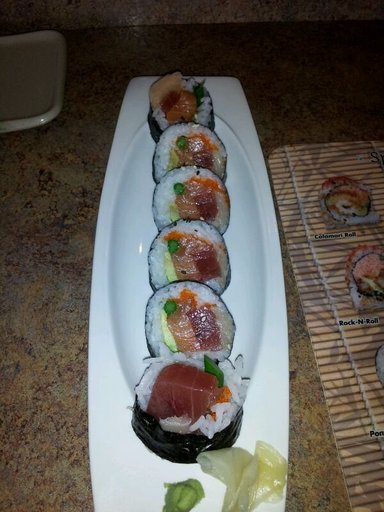

In [57]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# get all image paths
image_path_list=list(image_path.glob("*/*/*.jpg"))
# get a random image
random_image_path=random.choice(image_path_list)
# get the class of the image
image_class=random_image_path.parent.name
# open the image
img=Image.open(random_image_path)
img1=plt.imread(random_image_path)


# 5. Print metadata
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img


In [24]:
#turing our images into arrays
import numpy as np
import matplotlib.pyplot as plt


img_as_array=np.array(img)
img_as_array

array([[[ 45,  42,  23],
        [ 45,  42,  23],
        [ 46,  43,  24],
        ...,
        [ 62,  57,  37],
        [ 64,  59,  39],
        [ 63,  58,  38]],

       [[ 45,  42,  23],
        [ 45,  42,  23],
        [ 47,  44,  25],
        ...,
        [ 62,  57,  37],
        [ 64,  59,  39],
        [ 64,  59,  39]],

       [[ 45,  42,  23],
        [ 46,  43,  24],
        [ 47,  44,  25],
        ...,
        [ 61,  56,  36],
        [ 64,  59,  39],
        [ 64,  59,  39]],

       ...,

       [[ 81,  66,  37],
        [ 85,  70,  41],
        [ 89,  74,  45],
        ...,
        [ 98,  42,  25],
        [103,  47,  30],
        [104,  51,  33]],

       [[ 89,  74,  45],
        [ 94,  79,  50],
        [ 99,  84,  55],
        ...,
        [104,  49,  29],
        [110,  55,  35],
        [113,  58,  38]],

       [[ 93,  78,  49],
        [ 99,  84,  55],
        [104,  89,  60],
        ...,
        [111,  54,  35],
        [116,  61,  41],
        [119,  64,  44]]

In [42]:
import torch 
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from torch import nn


In [43]:
data_transform=transforms.Compose([
    # resize the image
    transforms.Resize(size=(64,64)),
    # Flip the images randomly on the horizontal for data augmentation
    transforms.RandomHorizontalFlip(p=0.5), # p = probability of flip, 0.5 = 50% chance
    # Turn the image into a torch.Tensor
    transforms.ToTensor()
])

In [48]:
data_transform(img).dtype,data_transform(img).shape

(torch.float32, torch.Size([3, 64, 64]))

In [75]:
def plot_transform_image(image_path , transform, n=3):
     """Plots a series of random images from image_paths.

    Will open n image paths from image_paths, transform them
    with transform and plot them side by side.

    Args:
        image_paths (list): List of target image paths. 
        transform (PyTorch Transforms): Transforms to apply to images.
        n (int, optional): Number of images to plot. Defaults to 3.
        seed (int, optional): Random seed for the random generator. Defaults to 42.
    """
     # Set random seed for reproducibility
     random.seed(42)
     image_path_list = list(image_path.glob("*/*/*.jpg"))
     # Create a figure to hold the subplots
     fig = plt.figure(figsize=(n * 5, 5))
     for i in range(n):
            # Choose a random image path
            random_image_path = random.choice(image_path_list)
            # Open the image
            img = Image.open(random_image_path)
            # Apply the transform to the image
            transformed_img = transform(img)
            # Add a subplot for the transformed image
            ax = fig.add_subplot(1, n, i + 1)
            # Convert the tensor to a numpy array and transpose it for plotting
            ax.imshow(transformed_img.permute(1, 2, 0))
            ax.axis("off")
            ax.set_title(random_image_path.name)
            
            

     

 
    



In [ ]:
plot_transform_image(image_path, data_transform, n=3)   

IndexError: Cannot choose from an empty sequence

<Figure size 1500x500 with 0 Axes>